# Training an egg detector

Notebook 02 found that confidence-based deferral does not separate from a
random control. The cause was identified there: every tile score comes from
a linear probe on frozen ImageNet features, which have never seen a parasite
egg. A model that cannot recognise what it is looking at cannot know when it
is wrong.

This notebook trains a scorer on `SHdataset_12k` — the annotated detection
archive from the same Zenodo record, disjoint from the 65 diagnosis patients.

At 27.8 GB against a 20 GB working directory, the archive is never downloaded
whole. Its index is read over HTTP range requests and members fetched
individually, which also means its structure can be inspected before
committing to anything.

In [1]:
!pip install -q remotezip

import requests, collections, pathlib
from remotezip import RemoteZip

REC = "6467268"
rec = requests.get(f"https://zenodo.org/api/records/{REC}", timeout=60).json()
meta = next(f for f in rec["files"] if f["key"] == "SHdataset_12k.zip")
URL  = meta["links"]["self"]

print(f"{meta['key']}  ·  {meta['size']/1e9:.2f} GB\n")

with RemoteZip(URL) as z:
    names = z.namelist()

print(f"{len(names):,} entries\n")
print("first 20:")
for n in names[:20]:
    print("  ", n)

exts = collections.Counter(pathlib.PurePosixPath(n).suffix.lower() for n in names)
print("\nfile types:", dict(exts))

depths = collections.Counter(n.rstrip("/").count("/") for n in names)
print("path depths:", dict(sorted(depths.items())))

SHdataset_12k.zip  ·  27.81 GB

24,108 entries

first 20:
   SHdataset_12k/test/
   SHdataset_12k/test/images/
   SHdataset_12k/test/images/10002.png
   SHdataset_12k/test/images/10006.png
   SHdataset_12k/test/images/10019.png
   SHdataset_12k/test/images/10033.png
   SHdataset_12k/test/images/10034.png
   SHdataset_12k/test/images/10044.png
   SHdataset_12k/test/images/10045.png
   SHdataset_12k/test/images/10056.png
   SHdataset_12k/test/images/10069.png
   SHdataset_12k/test/images/10070.png
   SHdataset_12k/test/images/10074.png
   SHdataset_12k/test/images/10075.png
   SHdataset_12k/test/images/10082.png
   SHdataset_12k/test/images/10084.png
   SHdataset_12k/test/images/10085.png
   SHdataset_12k/test/images/10093.png
   SHdataset_12k/test/images/10100.png
   SHdataset_12k/test/images/10103.png

file types: {'': 6, '.png': 24102}
path depths: {1: 2, 2: 4, 3: 24102}


### What is in the archive

24,102 PNGs across two splits, with two folders inside each. The count is
exactly twice 12,051, which suggests every image is paired with something —
most likely a mask. Confirming that decides the whole approach: pixel-level
annotations convert to tile labels directly, where bounding boxes or
image-level labels would not.

In [2]:
pairs = collections.Counter(
    "/".join(pathlib.PurePosixPath(n).parts[:3])
    for n in names if n.lower().endswith(".png")
)
for k, v in sorted(pairs.items()):
    print(f"{k:45s} {v:,}")

SHdataset_12k/test/images                     2,410
SHdataset_12k/test/masks                      2,410
SHdataset_12k/train/images                    9,641
SHdataset_12k/train/masks                     9,641


### One pair, looked at

Before planning anything, we will fetch a single image and its mask over
range requests and inspect them. Three facts decide what follows: the image
dimensions, the values the mask holds, and how much of a frame an egg
occupies. Together they set the tile size and the class balance to expect.

In [3]:
import io
import numpy as np
from PIL import Image

train_imgs  = sorted(n for n in names
                     if n.startswith("SHdataset_12k/train/images/") and n.endswith(".png"))
train_masks = sorted(n for n in names
                     if n.startswith("SHdataset_12k/train/masks/")  and n.endswith(".png"))

print(f"{len(train_imgs):,} images   {len(train_masks):,} masks")
print(f"first image : {train_imgs[0]}")
print(f"first mask  : {train_masks[0]}")
print(f"names match : {pathlib.PurePosixPath(train_imgs[0]).name == pathlib.PurePosixPath(train_masks[0]).name}\n")

with RemoteZip(URL) as z:
    img  = Image.open(io.BytesIO(z.read(train_imgs[0])))
    mask = Image.open(io.BytesIO(z.read(train_masks[0])))

m = np.array(mask)
print(f"image  {img.size}  mode {img.mode}")
print(f"mask   {mask.size}  mode {mask.mode}")
print(f"mask values {np.unique(m)[:10]}")
print(f"marked pixels {(m > 0).mean():.4%} of the frame")

9,641 images   9,641 masks
first image : SHdataset_12k/train/images/10001.png
first mask  : SHdataset_12k/train/masks/10001.png
names match : True

image  (2028, 1520)  mode RGB
mask   (2028, 1520)  mode L
mask values [0]
marked pixels 0.0000% of the frame


### Finding a positive example

Image 10001 has an empty mask, so nothing is known yet about how an egg is
marked. We will sample masks until some marked pixels turn up, then look at
the values they carry and how large the marked region is. That settles
whether a mask is binary or multi-class, whether it marks outlines or filled
shapes, and roughly what fraction of a frame an egg occupies.

In [4]:
from tqdm.auto import tqdm

SAMPLE = 40
found, empty = [], 0

with RemoteZip(URL) as z:
    for n in tqdm(train_masks[:SAMPLE], desc="sampling masks"):
        m = np.array(Image.open(io.BytesIO(z.read(n))))
        if (m > 0).any():
            found.append((n, m))
        else:
            empty += 1

print(f"\n{empty} of {SAMPLE} masks are empty, {len(found)} have markings\n")

for n, m in found[:3]:
    vals, counts = np.unique(m, return_counts=True)
    frac = (m > 0).mean()
    print(f"{pathlib.PurePosixPath(n).name}")
    print(f"   values {dict(zip(vals.tolist(), counts.tolist()))}")
    print(f"   marked {frac:.4%} of frame  ({(m>0).sum():,} px)")

sampling masks:   0%|          | 0/40 [00:00<?, ?it/s]


21 of 40 masks are empty, 19 have markings

10013.png
   values {0: 3041729, 255: 40831}
   marked 1.3246% of frame  (40,831 px)
10014.png
   values {0: 3017337, 255: 65223}
   marked 2.1159% of frame  (65,223 px)
10015.png
   values {0: 3058572, 255: 23988}
   marked 0.7782% of frame  (23,988 px)


### Turning masks into tile labels

The scorer this trains will be applied to tiles cut from the 65 diagnosis
patients, so it must be trained on tiles cut the same way: each 2028 × 1520
frame resized to 1024 × 768 and divided into a 3 × 4 grid of 256 × 256 tiles.
A detector trained at a different scale would see different-looking objects
at inference.

A tile's label comes from its region of the mask. The open question is how
many marked pixels should make a tile positive: one is too fragile, since an
egg clipped at a tile boundary leaves a sliver on the neighbour. Below, the
distribution of marked pixels per tile across a sample, which is what decides
the cut-off.

In [5]:
ROWS, COLS, PX = 3, 4, 256
SAMPLE2 = 120

per_tile = []
frames_with_egg = 0

with RemoteZip(URL) as z:
    for n in tqdm(train_masks[:SAMPLE2], desc="tiling masks"):
        m = Image.open(io.BytesIO(z.read(n))).resize((1024, 768), Image.NEAREST)
        a = (np.array(m) > 0)
        if a.any():
            frames_with_egg += 1
        for r in range(ROWS):
            for c in range(COLS):
                per_tile.append(a[r*PX:(r+1)*PX, c*PX:(c+1)*PX].sum())

per_tile = np.array(per_tile)

print(f"\nframes with any egg   {frames_with_egg} of {SAMPLE2}  ({frames_with_egg/SAMPLE2:.0%})")
print(f"tiles                 {len(per_tile):,}\n")

for t in (1, 50, 100, 250, 500, 1000):
    k = (per_tile >= t).sum()
    print(f"  >= {t:>4d} marked px   {k:5,} tiles  ({k/len(per_tile):.1%})")

nz = per_tile[per_tile > 0]
print(f"\namong tiles with any marking: median {np.median(nz):.0f} px, "
      f"min {nz.min()}, max {nz.max()}")

tiling masks:   0%|          | 0/120 [00:00<?, ?it/s]


frames with any egg   47 of 120  (39%)
tiles                 1,440

  >=    1 marked px     145 tiles  (10.1%)
  >=   50 marked px     140 tiles  (9.7%)
  >=  100 marked px     138 tiles  (9.6%)
  >=  250 marked px     134 tiles  (9.3%)
  >=  500 marked px     126 tiles  (8.8%)
  >= 1000 marked px     119 tiles  (8.3%)

among tiles with any marking: median 3208 px, min 3, max 14431


### The labelling rule

A tile is **positive** when at least 500 of its mask pixels are marked, and
**negative** when none are. Tiles between those two — 1 to 499 marked pixels,
1.3% of the sample — are **dropped rather than assigned a label.**

Those are eggs clipped by a tile boundary. Calling such a tile negative teaches
the scorer that a sliver of egg is clean urine, which is the opposite of what it
needs to learn; calling it positive teaches it that three pixels are enough.
Discarding them costs almost nothing and keeps both classes honest.

### Sizing the extraction before committing to it

Each read is a separate HTTP range request into a 27.8 GB archive, and the
masks alone ran at 0.8 s each. Reading all 9,641 pairs could take most of a
day, which would decide how this notebook is built — so the throughput is
measured on a small timed sample first, and the number of frames to use is
chosen from that measurement rather than from an assumption.

In [6]:
import time

N_TIME = 12
t0 = time.time()
with RemoteZip(URL) as z:
    for n in train_imgs[:N_TIME]:
        _ = Image.open(io.BytesIO(z.read(n))).convert("RGB")
img_s = (time.time() - t0) / N_TIME

mask_s = 98 / 120

print(f"image  {img_s:5.2f} s each")
print(f"mask   {mask_s:5.2f} s each")
print(f"pair   {img_s + mask_s:5.2f} s\n")

for n_frames in (500, 1000, 2000, 5000, 9641):
    hrs = n_frames * (img_s + mask_s) / 3600
    tiles = n_frames * 12
    print(f"  {n_frames:>5,} frames  ->  {tiles:>7,} tiles, "
          f"~{int(tiles * 0.101):>6,} positive   {hrs:5.1f} h")

image   2.50 s each
mask    0.82 s each
pair    3.32 s

    500 frames  ->    6,000 tiles, ~   606 positive     0.5 h
  1,000 frames  ->   12,000 tiles, ~ 1,212 positive     0.9 h
  2,000 frames  ->   24,000 tiles, ~ 2,424 positive     1.8 h
  5,000 frames  ->   60,000 tiles, ~ 6,060 positive     4.6 h
  9,641 frames  ->  115,692 tiles, ~11,684 positive     8.9 h


### Reading several members at once

Each read is one HTTP connection to Zenodo at roughly 0.6 MB/s, and the earlier
download showed that opening several connections at once raises the total.
Below, the same read is timed with 1, 4, 8 and 16 worker threads, each holding
its own handle on the archive, to find where the gain stops.

Throughput scales almost linearly to 8 workers — 2.74 s per image falls to
0.42 s, a 6.5× gain — and 16 workers is refused outright with HTTP 429. The
extraction therefore runs on 6, below the refusal point, which brings the full
9,641 pairs inside Kaggle's 12-hour session limit.

In [7]:
from concurrent.futures import ThreadPoolExecutor
import threading, time

_local = threading.local()

def _handle():
    if not hasattr(_local, "z"):
        _local.z = RemoteZip(URL)
    return _local.z

def read_one(n):
    return Image.open(io.BytesIO(_handle().read(n))).convert("RGB").size

MASK_RATIO = 0.82 / 3.87
cursor = 300

for W in (1, 4, 8, 16):
    try:
        with ThreadPoolExecutor(max_workers=W) as ex:
            list(ex.map(read_one, train_imgs[cursor:cursor + W]))   # warm the handles
            cursor += W

            batch = train_imgs[cursor:cursor + W * 3]
            cursor += len(batch)
            t0 = time.time()
            list(ex.map(read_one, batch))
            per_img = (time.time() - t0) / len(batch)

        per_pair = per_img * (1 + MASK_RATIO)
        print(f"{W:>2d} workers   {per_img:5.2f} s/image   {per_pair:5.2f} s/pair   "
              f"->  {2000*per_pair/3600:4.1f} h for 2,000   "
              f"{5000*per_pair/3600:4.1f} h for 5,000   "
              f"{9641*per_pair/3600:5.1f} h for all")

    except Exception as e:
        print(f"{W:>2d} workers   refused by Zenodo · {type(e).__name__}: {str(e)[:70]}")
        cursor += W * 4
        break

 1 workers    2.63 s/image    3.18 s/pair   ->   1.8 h for 2,000    4.4 h for 5,000     8.5 h for all
 4 workers    0.61 s/image    0.74 s/pair   ->   0.4 h for 2,000    1.0 h for 5,000     2.0 h for all
 8 workers    0.30 s/image    0.37 s/pair   ->   0.2 h for 2,000    0.5 h for 5,000     1.0 h for all
16 workers   refused by Zenodo · RemoteIOError: 429 Client Error: TOO MANY REQUESTS for url: https://zenodo.org/api/re


### Reading in a way that survives refusal

Eight parallel connections read six times faster than one, and sixteen are
refused outright. Sustained reading provokes refusals that a short burst never
sees, so the extraction runs on four connections and wraps every read in a
retry that waits up to four minutes before giving up — and a read that fails
even then costs one frame rather than ending the cell.

In [8]:
import random

FAILED = []

def read_member(n, attempts=10):
    for i in range(attempts):
        try:
            return _handle().read(n)
        except Exception:
            if hasattr(_local, "z"):
                try:    _local.z.close()
                except Exception: pass
                del _local.z
            time.sleep(min(2 ** i, 30) + random.random() * 2)
    FAILED.append(n)
    return None

print("read_member ready · 10 attempts · returns None on failure")

read_member ready · 10 attempts · returns None on failure


### Extracting the training tiles

Each frame is resized to 1024 × 768 and cut into twelve 256 × 256 tiles, the same
geometry used on the 65 diagnosis patients. Every positive tile is kept and about
one in four empty tiles, which fits the result inside the 20 GB working directory,
written as one shard per thousand frames so an interrupted run can resume.

In [9]:
with ThreadPoolExecutor(max_workers=6) as ex:
    list(ex.map(read_member, train_imgs[700:706]))        # warm the six handles

    t0 = time.time()
    got = list(ex.map(read_member, train_imgs[706:742]))
    per = (time.time() - t0) / 36

print(f"36 images · 6 warm workers · {per:.2f} s each")

36 images · 6 warm workers · 0.40 s each


### Extracting the training tiles

Every frame is resized to 1024 × 768 and cut into a 3 × 4 grid of 256 × 256
tiles — the same geometry the 65 diagnosis patients were tiled with, so the
scorer sees objects at the same scale in training and at inference.

Keeping all 115,692 tiles would need 22.7 GB against a 20 GB working directory.
Every positive tile is kept, since those are the scarce half of the problem, and
negatives are kept at roughly one in four to land near two negatives per
positive — enough for the classifier to learn what clean urine looks like
without spending the disk on a hundred thousand near-identical empty fields.

Results are written as a shard per 250 frames, so an interrupted run resumes
from the last completed shard rather than starting over.

In [10]:
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np

OUT = Path("/kaggle/working/tiles"); OUT.mkdir(parents=True, exist_ok=True)

ROWS, COLS, PX = 3, 4, 256
POS_MIN  = 500          # marked pixels for a tile to count as positive
NEG_PCT  = 23           # percent of empty tiles kept
CHUNK    = 250          # frames per shard
WORKERS  = 4

assert [n.split("/")[-1] for n in train_imgs] == \
       [n.split("/")[-1] for n in train_masks], "image/mask filenames not aligned"

def process_frame(job):
    idx, iname, mname = job
    ib = read_member(iname)
    mb = read_member(mname)
    if ib is None or mb is None:
        return []                           # unreadable frame, skipped not fatal

    a = np.asarray(Image.open(io.BytesIO(ib)).convert("RGB")
                     .resize((1024, 768), Image.BILINEAR))
    m = np.asarray(Image.open(io.BytesIO(mb))
                     .resize((1024, 768), Image.NEAREST)) > 0

    out = []
    for t in range(ROWS * COLS):
        r, c = divmod(t, COLS)
        sl = (slice(r*PX, (r+1)*PX), slice(c*PX, (c+1)*PX))
        n  = int(m[sl].sum())

        if n >= POS_MIN:
            y = 1
        elif n == 0 and (idx * 7919 + t * 104729) % 100 < NEG_PCT:
            y = 0
        else:
            continue                        # sliver, or an unsampled negative

        out.append((a[sl].copy(), y))
    return out

jobs = [(i, train_imgs[i], train_masks[i]) for i in range(len(train_imgs))]
t_start = time.time()

with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    for s0 in range(0, len(jobs), CHUNK):
        shard = OUT / f"shard_{s0:05d}.npz"
        if shard.exists():
            continue

        batch = jobs[s0:s0 + CHUNK]
        X, Y = [], []
        for res in tqdm(ex.map(process_frame, batch), total=len(batch),
                        desc=f"{s0:>5d}", leave=False):
            for tile, y in res:
                X.append(tile); Y.append(y)

        X = np.stack(X); Y = np.array(Y, dtype=np.int8)
        np.savez(shard, X=X, y=Y)
        done = s0 + len(batch)
        print(f"{shard.name} · {len(Y):>5,} tiles · {int(Y.sum()):>5,} pos ({Y.mean():.0%}) · "
              f"{done:>5,}/{len(jobs)} frames · {(time.time()-t_start)/60:>4.0f} min · "
              f"{len(FAILED)} failed")

    0:   0%|          | 0/250 [00:00<?, ?it/s]

shard_00000.npz ·   970 tiles ·   386 pos (40%) ·   250/9641 frames ·    4 min · 0 failed


  250:   0%|          | 0/250 [00:00<?, ?it/s]

shard_00250.npz ·   873 tiles ·   256 pos (29%) ·   500/9641 frames ·    9 min · 0 failed


  500:   0%|          | 0/250 [00:00<?, ?it/s]

...

shard_09000.npz ·   824 tiles ·   169 pos (21%) · 9,250/9641 frames ·  169 min · 0 failed


 9250:   0%|          | 0/250 [00:00<?, ?it/s]

shard_09250.npz ·   789 tiles ·   144 pos (18%) · 9,500/9641 frames ·  173 min · 0 failed


 9500:   0%|          | 0/141 [00:00<?, ?it/s]

shard_09500.npz ·   467 tiles ·   110 pos (24%) · 9,641/9641 frames ·  176 min · 0 failed


### Taking stock of the extracted tiles

Before training anything, the shards are counted — how many tiles, how many
positive, and how much disk they occupy. Reading every shard also doubles as an
integrity check, since a file damaged by the interrupted session would fail to
open here rather than halfway through training.

In [11]:
import glob, os

files = sorted(glob.glob("/kaggle/working/tiles/shard_*.npz"))
n_tiles = n_pos = 0
for f in files:
    with np.load(f) as d:
        y = d["y"]
    n_tiles += len(y); n_pos += int(y.sum())

print(f"shards      {len(files)}  (expected 39)")
print(f"tiles       {n_tiles:,}")
print(f"positive    {n_pos:,}  ({n_pos/n_tiles:.1%})")
print(f"negative    {n_tiles - n_pos:,}")
print(f"on disk     {sum(os.path.getsize(f) for f in files)/1e9:.2f} GB")

shards      39  (expected 39)
tiles       32,277
positive    7,609  (23.6%)
negative    24,668
on disk     6.35 GB


### Consolidating the shards for training

The 39 shards are joined into a single memory-mapped array so training can draw
random batches across the whole set without holding 6 GB in memory at once. Each
tile also records which shard it came from, since a shard is 250 consecutive
frames and that grouping is what keeps train and validation frame-disjoint.

In [12]:
TD = Path("/kaggle/working/trainset"); TD.mkdir(exist_ok=True)

sizes = []
for f in files:
    with np.load(f) as d:
        sizes.append(len(d["y"]))
N = sum(sizes)

X = np.lib.format.open_memmap(TD/"X.npy", mode="w+", dtype=np.uint8, shape=(N, PX, PX, 3))
y = np.empty(N, dtype=np.int8)
g = np.empty(N, dtype=np.int16)

at = 0
for i, f in enumerate(tqdm(files, desc="consolidating")):
    with np.load(f) as d:
        n = len(d["y"])
        X[at:at+n] = d["X"]
        y[at:at+n] = d["y"]
        g[at:at+n] = i
    at += n

X.flush()
np.save(TD/"y.npy", y)
np.save(TD/"g.npy", g)

assert at == N
print(f"X {X.shape}  {X.nbytes/1e9:.2f} GB")
print(f"y {y.shape}  {int(y.sum()):,} positive")
print(f"g {g.shape}  {g.max()+1} shard groups")
print(f"disk free {os.statvfs('/kaggle/working').f_bavail * 4096 / 1e9:.1f} GB")

consolidating:   0%|          | 0/39 [00:00<?, ?it/s]

X (32277, 256, 256, 3)  6.35 GB
y (32277,)  7,609 positive
g (32277,)  39 shard groups
disk free 8.2 GB


### Looking at the labels before training on them

Eight positive and eight negative tiles, drawn at random. Everything up to this
point has been arithmetic on mask pixels — this is the first time the tiles are
seen as images, and the only way to confirm that a tile labelled positive
actually contains a visible egg.

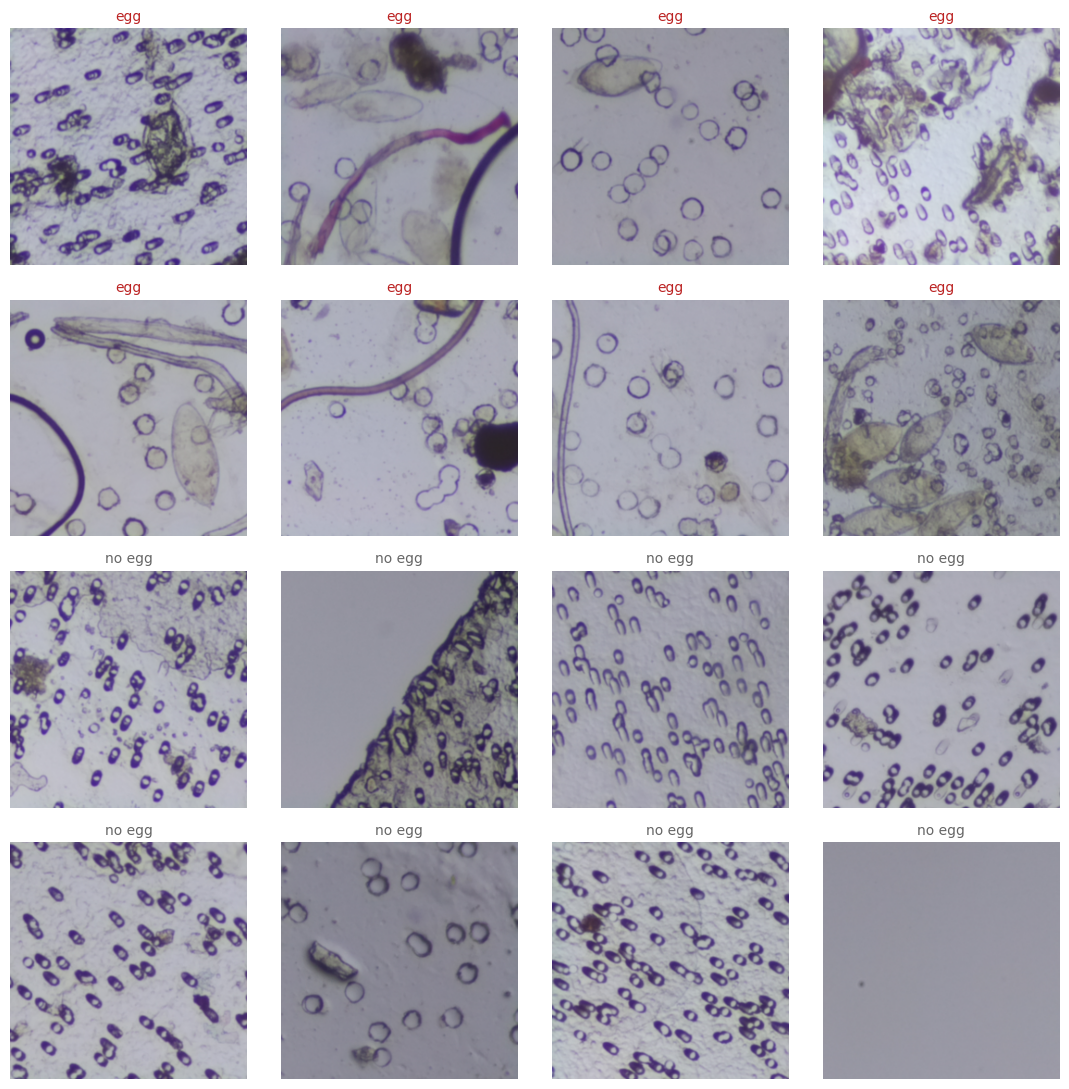

In [13]:
import matplotlib.pyplot as plt

RNG   = np.random.default_rng(0)
pos_i = RNG.choice(np.flatnonzero(y == 1), 8, replace=False)
neg_i = RNG.choice(np.flatnonzero(y == 0), 8, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, i in zip(axes.flat[:8], pos_i):
    ax.imshow(X[i]); ax.set_title("egg", fontsize=10, color="#b22")
for ax, i in zip(axes.flat[8:], neg_i):
    ax.imshow(X[i]); ax.set_title("no egg", fontsize=10, color="#666")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Reloading after the GPU restart

Switching accelerator restarts the kernel, so the variables are gone while the
files remain. The tiles are re-opened from disk — memory-mapped, not loaded —
and the GPU is confirmed before anything is trained on it.

In [14]:
import numpy as np, os, torch
from pathlib import Path

TD = Path("/kaggle/working/trainset")
X = np.load(TD/"X.npy", mmap_mode="r")
y = np.load(TD/"y.npy")
g = np.load(TD/"g.npy")

print(f"X {X.shape}   y {y.shape}   {int(y.sum()):,} positive ({y.mean():.1%})")
print(f"groups {g.max()+1}")
print(f"torch {torch.__version__} · cuda {torch.cuda.is_available()} · "
      f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU'}")

X (32277, 256, 256, 3)   y (32277,)   7,609 positive (23.6%)
groups 39
torch 2.11.0+cu128 · cuda True · Tesla T4


### Splitting train and validation by shard

Each shard is 250 consecutive frames, so splitting whole shards keeps every
tile from a given frame on one side of the line — twelve tiles of the same
field of view are near-duplicates, and letting them straddle the split would
validate the model on what it had memorised.

Every fifth shard is held out rather than a contiguous block, because the
positive rate runs from 4% to 49% depending on position in the archive and a
contiguous slice would make the two sides incomparable.

In [15]:
VAL_SHARDS = np.arange(2, 39, 5)          # 2, 7, 12, 17, 22, 27, 32, 37
is_val = np.isin(g, VAL_SHARDS)

tr = np.flatnonzero(~is_val)
va = np.flatnonzero(is_val)

assert not (set(g[tr].tolist()) & set(g[va].tolist())), "shard appears on both sides"

print(f"train  {len(tr):>6,} tiles · {int(y[tr].sum()):>5,} positive ({y[tr].mean():.1%}) · "
      f"{39 - len(VAL_SHARDS)} shards")
print(f"val    {len(va):>6,} tiles · {int(y[va].sum()):>5,} positive ({y[va].mean():.1%}) · "
      f"{len(VAL_SHARDS)} shards")
print(f"\nheld out: {VAL_SHARDS.tolist()}")

train  25,615 tiles · 6,078 positive (23.7%) · 31 shards
val     6,662 tiles · 1,531 positive (23.0%) · 8 shards

held out: [2, 7, 12, 17, 22, 27, 32, 37]


### Defining the detector

A ResNet18 pre-trained on ImageNet, with its 1000-class head replaced by a
single output: the log-odds that this tile contains an egg. Unlike notebook 02,
the whole network is trained, so the features themselves adapt to microscopy
rather than staying generic.

Each training tile is randomly flipped and rotated. A tile has no natural
orientation — the slide could have been placed any way round — so these are
transformations the model should be invariant to, and they multiply the
effective size of the training set eightfold.

In [16]:
import torch.nn as nn, torchvision
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

DEV  = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class TileSet(Dataset):
    def __init__(self, idx, augment):
        self.idx, self.augment = idx, augment

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = int(self.idx[i])
        a = torch.from_numpy(np.array(X[j])).permute(2, 0, 1).float().div_(255)
        if self.augment:
            if torch.rand(()) < 0.5: a = torch.flip(a, [2])
            if torch.rand(()) < 0.5: a = torch.flip(a, [1])
            a = torch.rot90(a, int(torch.randint(0, 4, (1,))), [1, 2])
        return (a - MEAN) / STD, torch.tensor(float(y[j]))

def make_model():
    m = torchvision.models.resnet18(
        weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 1)
    return m.to(DEV)

print("defined: TileSet, make_model")

defined: TileSet, make_model


### Training

Six passes over the 25,615 training tiles, evaluating on the held-out shards
after each. The checkpoint is kept whenever validation improves, so the model
that survives is the best one seen rather than whatever the last epoch left
behind.

In [17]:
EPOCHS, BATCH, LR = 6, 64, 1e-4

dl_tr = DataLoader(TileSet(tr, True),  batch_size=BATCH, shuffle=True,
                   num_workers=2, pin_memory=True, drop_last=True)
dl_va = DataLoader(TileSet(va, False), batch_size=BATCH, shuffle=False,
                   num_workers=2, pin_memory=True)

model  = make_model()
opt    = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(dl_tr))
lossf  = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

best = -1.0
for ep in range(1, EPOCHS + 1):
    model.train(); run = 0.0
    for xb, yb in tqdm(dl_tr, desc=f"epoch {ep}", leave=False):
        xb, yb = xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = lossf(model(xb).squeeze(1), yb)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        run += loss.item() * len(yb)

    model.eval(); P = []
    with torch.no_grad():
        for xb, _ in dl_va:
            with torch.autocast("cuda", dtype=torch.float16):
                P.append(torch.sigmoid(model(xb.to(DEV)).squeeze(1)).float().cpu())
    p   = torch.cat(P).numpy()
    auc = roc_auc_score(y[va], p)
    ap  = average_precision_score(y[va], p)

    flag = ""
    if auc > best:
        best = auc
        torch.save(model.state_dict(), "/kaggle/working/detector.pt")
        np.save("/kaggle/working/val_scores.npy", p)
        flag = " · saved"
    print(f"epoch {ep}  loss {run/len(tr):.4f}  val AUROC {auc:.4f}  AP {ap:.4f}{flag}")

print(f"\nbest val AUROC {best:.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


epoch 1:   0%|          | 0/400 [00:00<?, ?it/s]

epoch 1  loss 0.2388  val AUROC 0.9768  AP 0.9352 · saved


epoch 2:   0%|          | 0/400 [00:00<?, ?it/s]

...

epoch 5:   0%|          | 0/400 [00:00<?, ?it/s]

epoch 5  loss 0.1189  val AUROC 0.9845  AP 0.9565 · saved


epoch 6:   0%|          | 0/400 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6dd0e61b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6dd0e61b20>
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

AssertionError    self._shutdown_workers(): 
can only test a child process
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch 6  loss 0.1100  val AUROC 0.9847  AP 0.9558 · saved

best val AUROC 0.9847


### Where the detector fails

The six empty tiles it scored highest and the six egg tiles it scored lowest.
A detector is characterised by its mistakes more than its successes, and these
are the cases that will drive the patient-level errors downstream.

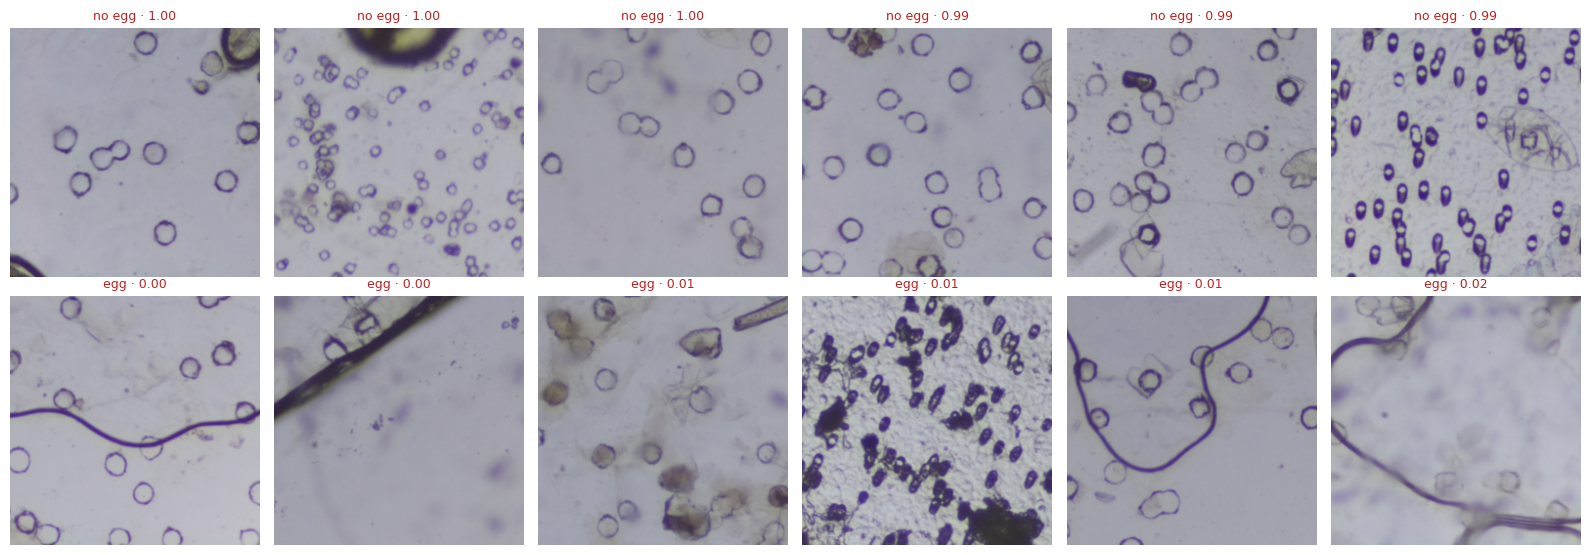

In [18]:
p   = np.load("/kaggle/working/val_scores.npy")
yv  = y[va]

fp = va[np.argsort(-np.where(yv == 0, p, -1))[:6]]     # empty tiles, highest scored
fn = va[np.argsort( np.where(yv == 1, p, 2))[:6]]      # egg tiles, lowest scored
sp = p[np.argsort(-np.where(yv == 0, p, -1))[:6]]
sn = p[np.argsort( np.where(yv == 1, p, 2))[:6]]

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for ax, i, s in zip(axes[0], fp, sp):
    ax.imshow(X[i]); ax.set_title(f"no egg · {s:.2f}", fontsize=9, color="#b22")
for ax, i, s in zip(axes[1], fn, sn):
    ax.imshow(X[i]); ax.set_title(f"egg · {s:.2f}", fontsize=9, color="#b22")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/fig_detector_errors.png", dpi=110)
plt.show()

### What this notebook established

A tile-level egg detector trained on 25,615 tiles from 7,641 frames and
validated on 6,662 tiles from 2,000 frames it never saw: **AUROC 0.985,
average precision 0.957**. Validation stopped improving after the fourth
epoch while training loss kept falling, so the fourth-epoch checkpoint is the
one kept.

Inspecting the errors suggests a share of them are label noise rather than
model failure — several of the highest-scoring negatives contain objects that
appear to be unannotated eggs, and several of the lowest-scoring positives
show no visible egg. Tile labels inherit whatever the expert masks omitted,
which places a ceiling on any score measured against them.

The detector replaces the frozen ImageNet features used in notebook 02, where
tile scores carried no notion of what an egg looks like. Whether scores that
now mean something also produce deferral that beats random deferral is the
question the next notebook asks.

In [19]:
import os, shutil
shutil.rmtree("/kaggle/working/tiles", ignore_errors=True)
print("kept:", sorted(os.listdir("/kaggle/working")))
print("size:", sum(os.path.getsize(os.path.join(dp, f))
                   for dp, _, fs in os.walk("/kaggle/working") for f in fs) / 1e9, "GB")

kept: ['__notebook__.ipynb', 'detector.pt', 'fig_detector_errors.png', 'trainset', 'val_scores.npy']
size: 6.395148666 GB
